# PyTorch training on Major TOM

Two ways to train a PyTorch model on Major TOM samples:

    A. Core datasets:  Core-S2L2A metadata (Hugging Face) -> filter by points, dates, cloud cover
                         -> filter_download (GeoTIFF folders) -> majortom.dataset.MajorTOM -> DataLoader
    B. Your own build: cells -> majortom.build (Sentinel-2 L2A inputs, ESA WorldCover labels)
                         -> majortom.release (TACO dataset, rumi files) -> Dataset reading whole batches
                         -> DataLoader -> a small land-cover segmentation model

**Route B is the recommended one.** Major TOM Core (2024) was built with code that predates the `majortom` package:
its samples are GeoTIFFs inside Parquet files, its window is the older 1,068 px one, and its stored georeferencing is
off by up to half a pixel (corrected by the readers, [SPEC section 7](https://github.com/ESA-PhiLab/Major-TOM/blob/refactor/v1/docs/SPEC.md)). Route B uses the
current tools: the sample window of the specification, any product and archive, and TACO datasets with rumi files,
which read a whole batch in one call. Route A stays for working with the published Core samples.

The first notebook, [00-Major-TOM](https://github.com/ESA-PhiLab/Major-TOM/blob/refactor/v1/00-Major-TOM.ipynb), explains the grid, `majortom.build` and
`majortom.release`. A GPU helps for section 3; everything else runs on a CPU.

## 1. Install

On Colab or a fresh environment (restart the runtime after installing on Colab).

In [ ]:
%pip install -q "majortom[build,release,torch] @ git+https://github.com/ESA-PhiLab/Major-TOM@refactor/v1" matplotlib

In [2]:
import warnings
warnings.filterwarnings("ignore", message="Arrow output on a DB-API result")       # taco-eo, harmless
warnings.filterwarnings("ignore", message="IProgress not found")                   # tqdm outside Jupyter widgets
warnings.filterwarnings("ignore", message="Not enough data was used to sample")    # fsspec: one extra request for a large footer

import time
from pathlib import Path
import fsspec
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

https = fsspec.filesystem("https")
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

device: cuda


## 2. Route A: Core datasets

### 2.1 Cells for points of interest

Volcanoes from a public table (plotly's example datasets); the Italian ones, each mapped to its cell.

In [3]:
from majortom.cells import cells_from_points

volcanoes = pd.read_csv("https://raw.githubusercontent.com/plotly/datasets/master/volcano_db.csv", encoding="ISO-8859-1")
volcanoes = volcanoes[volcanoes.Country == "Italy"].rename(columns={"Longitude": "lon", "Latitude": "lat"})
points = cells_from_points(volcanoes[["Volcano Name", "lon", "lat"]])
points[["grid_cell", "Volcano Name", "row", "col"]]

,grid_cell,Volcano Name,row,col
0,464U_105R,"Albano, Monte",464,105
1,454U_119R,Campi Flegrei,454,119
2,413U_112R,Campi Flegrei Mar Sicilia,413,112
3,420U_132R,Etna,420,132
4,453U_117R,Ischia,453,117
5,481U_88R,Larderello,481,88
6,428U_130R,Lipari,428,130
7,439U_127R,Palinuro,439,127
8,409U_107R,Pantelleria,409,107
9,431U_132R,Stromboli,431,132


### 2.2 Filter the Core metadata

`metadata.parquet` has one row per sample. A filter on `grid_row_u` and `grid_col_r` reads only the row groups that
hold those rows and columns (a filter on `grid_cell` would read the whole file); the exact cells are then picked
with `isin`. `filter_metadata` filters by dates (as `"YYYYMMDD"`, the format of `timestamp`), cloud cover (percent)
and the share without data. Reading the metadata takes one to two minutes.

In [4]:
from majortom import filter_metadata

url = "https://huggingface.co/datasets/Major-TOM/Core-S2L2A/resolve/main/metadata.parquet"
meta = pd.read_parquet(url, filesystem=https, filters=[("grid_row_u", "in", sorted(set(points.row))),
                                                      ("grid_col_r", "in", sorted(set(points.col)))])
meta = meta[meta.grid_cell.isin(points.grid_cell)]
chosen = filter_metadata(meta, daterange=("20170101", "20241231"), cloud_cover=(0, 10), nodata=(0, 0))
print(len(meta), "Core-S2L2A samples at the volcanoes,", len(chosen), "with cloud cover up to 10% and no missing data")
chosen[["grid_cell", "timestamp", "cloud_cover", "product_id"]]

13 Core-S2L2A samples at the volcanoes, 8 with cloud cover up to 10% and no missing data


,grid_cell,timestamp,cloud_cover,product_id
15,413U_112R,20210724T100029,0.000000,S2B_MSIL2A_20210724T100029_N0500_R122_T33STB_2...
32,420U_132R,20211220T094411,0.159299,S2A_MSIL2A_20211220T094411_N0500_R036_T33SVB_2...
53,428U_130R,20230621T094549,0.000000,S2B_MSIL2A_20230621T094549_N0509_R079_T33SVC_2...
65,431U_132R,20220422T095031,8.724435,S2A_MSIL2A_20220422T095031_N9999_R079_T33SWC_2...
73,439U_127R,20190806T095031,0.000000,S2A_MSIL2A_20190806T095031_N0500_R079_T33SVD_2...
93,454U_119R,20170831T095029,0.000000,S2B_MSIL2A_20170831T095029_N0208_R079_T33TVF_2...
109,474U_97R,20230304T101021,0.000088,S2A_MSIL2A_20230304T101021_N0509_R022_T32TQN_2...
119,481U_88R,20171205T101359,4.241976,S2B_MSIL2A_20171205T101359_N0206_R022_T32TPN_2...


### 2.3 Download and load with the Core Dataset

`filter_download` writes each sample as a folder of GeoTIFFs (`<local_dir>/<source_name>/<row>/<grid_cell>/<product_id>/B04.tif`).
With `by_row=True` it reads only each sample's row group over HTTP; without it, it downloads every image Parquet
file the samples are in (several GB each). `majortom.dataset.MajorTOM` reads those folders: each item is a dict with
the metadata row and one tensor per band.

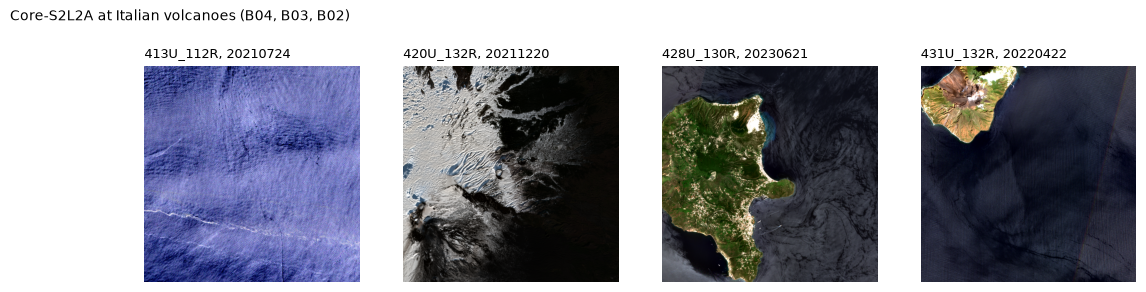

In [5]:
from torch.utils.data import DataLoader
from majortom import filter_download
from majortom.dataset import MajorTOM

filter_download(chosen, local_dir="core", source_name="L2A", by_row=True, tif_columns=["B04", "B03", "B02"])
core = MajorTOM(chosen, local_dir="core/L2A", tif_bands=["B04", "B03", "B02"], png_bands=[], tif_transforms=None)
loader = DataLoader(core, batch_size=4, collate_fn=lambda items: items)     # items keep their metadata rows
batch = next(iter(loader))
fig, axes = plt.subplots(1, len(batch), figsize=(3.2 * len(batch), 3.4), squeeze=False)
for ax, item in zip(axes[0], batch):
    rgb = np.concatenate([item[b] for b in ("B04", "B03", "B02")]).transpose(1, 2, 0).astype(float)
    lo, hi = np.percentile(rgb, (1, 99))                                   # stretch per image
    ax.imshow(np.clip((rgb - lo) / (hi - lo), 0, 1)), ax.axis("off")
    ax.set_title(f"{item['meta'].grid_cell}, {item['meta'].timestamp[:8]}", loc="left", fontsize=9)
fig.suptitle("Core-S2L2A at Italian volcanoes (B04, B03, B02)", x=0.02, ha="left", fontsize=10);

### 2.4 Reading Core without downloading

Three ways to feed Core samples to a DataLoader without a local copy:

| Approach | What it reads | Filter before reading | Random access |
|---|---|---|---|
| Hugging Face `datasets`, `streaming=True` | the image Parquet files in stored order; every sample's whole row (all bands and the thumbnail; Core-S2L2A: 22.95 TB / 2,245,886 samples = 10.2 MB per sample) | no: filters run on rows already fetched | no: shuffling only within a buffer |
| `read_row` in a Dataset (below) | one sample's row group, only the chosen bands | yes: on the metadata table | yes |
| a TACO dataset from its URL (section 3.7) | the catalogue once, then the bytes of each batch's files | yes: SQL on the catalogue | yes |

**Streaming with `datasets` is not recommended for Core**: to reach the samples of one region or period it reads
through the files in their stored order, fetching every sample on the way in full. It fits one pass over the whole
dataset in file order. For reference only (not run here):

    import datasets
    stream = datasets.load_dataset("Major-TOM/Core-S2L2A", streaming=True, split="train")
    sample = next(iter(stream))            # one whole row: every band as GeoTIFF bytes, the thumbnail, metadata

`read_row` reads only what the filtered metadata points at: the sample's row group in its image Parquet file, and
in it only the columns asked for.

In [6]:
from torch.utils.data import Dataset
from majortom import read_row

class CoreRows(Dataset):
    """Core samples read over HTTP: one row group per sample, only the chosen bands."""

    def __init__(self, meta: pd.DataFrame, bands=("B04", "B03", "B02")):
        self.meta, self.bands = meta.reset_index(drop=True), list(bands)

    def __len__(self):
        return len(self.meta)

    def __getitem__(self, i):
        data = read_row(self.meta.iloc[i], columns=self.bands)             # dict: band -> array
        return torch.from_numpy(np.stack([data[b] for b in self.bands]).astype(np.int32))

start = time.perf_counter()
batch = next(iter(DataLoader(CoreRows(chosen), batch_size=4, num_workers=4)))
print(tuple(batch.shape), f"in {time.perf_counter() - start:.1f} s, nothing written to disk")

(4, 3, 1068, 1068) in 6.2 s, nothing written to disk


## 3. Route B: build, release and train

### 3.1 Cells and samples

The cells of a box from Loch Lomond to Glasgow: water, forest, grassland, cropland and built-up areas. For each cell,
`majortom.build` reads a Sentinel-2 L2A sample (summer 2024, the clearest scene) and an ESA WorldCover 2021 sample
over the same window, from Planetary Computer (no account). Re-running reuses samples already built.

In [7]:
from majortom import build

cells = build.cells_in((-4.9, 55.75, -3.9, 56.25))
errors = build.download(cells, "sentinel-2-l2a", "2024-06-01/2024-08-31", outdir="chips")
errors = pd.concat([errors, build.download(cells, "esa-worldcover", "2021", outdir="chips")])
print(len(cells), "cells;", len(errors), "samples failed")
errors

sentinel-2-l2a:   0%|          | 0/49 [00:00<?, ?it/s]

sentinel-2-l2a: 100%|██████████| 49/49 [00:00<00:00, 270066.88it/s]

49 samples in chips/sentinel-2-l2a, 0 failed


esa-worldcover:   0%|          | 0/49 [00:00<?, ?it/s]

esa-worldcover: 100%|██████████| 49/49 [00:00<00:00, 306747.61it/s]

49 samples in chips/esa-worldcover, 0 failed
49 cells; 0 samples failed


,index,grid_cell,error


### 3.2 Release as TACO datasets

Each product becomes its own TACO dataset (rumi files, one per pixel-size group, and a catalogue). The catalogue
column `majortom:code` is the cell, so inputs and labels join on it. In the `10m` group, bands are in the
product's order: Sentinel-2 `B02, B03, B04, B08`, WorldCover `map` (classes).

In [8]:
import taco
from majortom.release import release

for product in ("sentinel-2-l2a", "esa-worldcover"):
    release(sorted(Path(f"chips/{product}").glob("*.npz")), f"release/{product}/{product}.zip", id=product,
            description=f"{product} around Loch Lomond, built with majortom.build", licenses=["CC-BY-4.0"],
            providers=["Your Name"], geoenrich=False, overwrite=True)

def files(product: str) -> pd.DataFrame:
    """One row per sample: its cell and the location and header of its 10 m file."""
    query = 'SELECT "majortom:code" AS cell, "10m.rumi::location" AS location, "10m.rumi::header" AS header FROM dataset'
    return taco.open_dataset(f"release/{product}").sql(query).to_pandas()

table = files("sentinel-2-l2a").merge(files("esa-worldcover"), on="cell", suffixes=("_s2", "_wc"))
print(len(table), "cells with both inputs and labels, e.g.", ", ".join(table.cell[:3]))

49 cells with both inputs and labels, e.g. MT10km_0626U_0025L, MT10km_0626U_0026L, MT10km_0626U_0027L


### 3.3 A Dataset that reads whole batches

`rumi.read_many` decodes the files of a whole batch in one call and returns one array with the batch on the first
axis. The Dataset therefore implements `__getitems__` (a batch of indices) instead of `__getitem__`, and the
DataLoader's `collate_fn` passes the batch through. Each sample is a random 256 x 256 crop of a cell, flipped at
random (training only); WorldCover classes (10, 20, ..., 100) become indices 0 to 10.

A few cells are held out for validation, so the scores are on places the model has not seen.

In [9]:
import rumi

CLASSES = {10: "tree cover", 20: "shrubland", 30: "grassland", 40: "cropland", 50: "built-up", 60: "bare",
           70: "snow and ice", 80: "water", 90: "herbaceous wetland", 95: "mangroves", 100: "moss and lichen"}
LOOKUP = np.full(256, 255, np.int64)                                   # 255: no label (ignored by the loss)
LOOKUP[list(CLASSES)] = np.arange(len(CLASSES))
OFFSET, SCALE = 1000, 10000                                            # Sentinel-2 L2A from baseline 04.00: value = DN - 1000

class Crops(Dataset):
    """Random crops of cells; one rumi.read_many call per batch and per product."""

    def __init__(self, table: pd.DataFrame, crops_per_cell: int = 16, size: int = 256, train: bool = True):
        self.rows, self.size, self.train = table.to_dict("records"), size, train
        self.length = len(self.rows) * crops_per_cell

    def __len__(self):
        return self.length

    def __getitems__(self, indices):
        rng = np.random.default_rng(None if self.train else list(indices))    # validation: the same crops every epoch
        rows = [self.rows[i % len(self.rows)] for i in indices]
        x = rumi.read_many([r["location_s2"] for r in rows], [r["header_s2"] for r in rows])    # (n, 4, 1056, 1056)
        y = rumi.read_many([r["location_wc"] for r in rows], [r["header_wc"] for r in rows])    # (n, 1, 1056, 1056)
        i, j = rng.integers(0, x.shape[-1] - self.size, (2, len(rows)))
        xs = np.stack([x[k, :, a:a + self.size, b:b + self.size] for k, (a, b) in enumerate(zip(i, j))])
        ys = np.stack([y[k, 0, a:a + self.size, b:b + self.size] for k, (a, b) in enumerate(zip(i, j))])
        if self.train and rng.random() < 0.5:
            xs, ys = xs[..., ::-1], ys[..., ::-1]
        xs = (xs.astype(np.float32) - OFFSET) / SCALE
        return torch.from_numpy(xs.copy()), torch.from_numpy(LOOKUP[ys])

rng = np.random.default_rng(0)
held_out = rng.choice(len(table), size=max(1, len(table) // 6), replace=False)
val_table, train_table = table.iloc[held_out], table.drop(table.index[held_out])
batch = lambda items: items                                            # __getitems__ already returns the batch
train = DataLoader(Crops(train_table), batch_size=16, shuffle=True, collate_fn=batch, num_workers=4, persistent_workers=True)
val = DataLoader(Crops(val_table, train=False), batch_size=16, collate_fn=batch)
x, y = next(iter(train))
print(len(train_table), "training cells,", len(val_table), "validation cells; a batch:", tuple(x.shape), tuple(y.shape))

41 training cells, 8 validation cells; a batch: (16, 4, 256, 256) (16, 256, 256)


### 3.4 A small U-Net

Two levels down and up, with skip connections: about 0.5 M parameters, enough to show the loop. Cross-entropy
ignores pixels without a label.

In [10]:
from torch import nn

def block(a: int, b: int) -> nn.Sequential:
    return nn.Sequential(nn.Conv2d(a, b, 3, padding=1), nn.BatchNorm2d(b), nn.ReLU(),
                         nn.Conv2d(b, b, 3, padding=1), nn.BatchNorm2d(b), nn.ReLU())

class UNet(nn.Module):
    def __init__(self, bands: int = 4, classes: int = len(CLASSES), w: int = 32):
        super().__init__()
        self.e1, self.e2, self.mid = block(bands, w), block(w, 2 * w), block(2 * w, 4 * w)
        self.u2, self.d2 = nn.ConvTranspose2d(4 * w, 2 * w, 2, 2), block(4 * w, 2 * w)
        self.u1, self.d1 = nn.ConvTranspose2d(2 * w, w, 2, 2), block(2 * w, w)
        self.out, self.pool = nn.Conv2d(w, classes, 1), nn.MaxPool2d(2)

    def forward(self, x):
        e1 = self.e1(x)
        e2 = self.e2(self.pool(e1))
        m = self.mid(self.pool(e2))
        d2 = self.d2(torch.cat([self.u2(m), e2], 1))
        return self.out(self.d1(torch.cat([self.u1(d2), e1], 1)))

model = UNet().to(device)
print(sum(p.numel() for p in model.parameters()) / 1e6, "M parameters")

0.468427 M parameters


### 3.5 Train

Batches move to the GPU whole (`non_blocking=True` from pinned memory); bf16 autocast on a GPU. Each epoch reports
the training loss and the validation pixel accuracy.

In [11]:
optimiser = torch.optim.AdamW(model.parameters(), lr=2e-3)
loss_fn = nn.CrossEntropyLoss(ignore_index=255)
amp = dict(device_type="cuda", dtype=torch.bfloat16, enabled=device == "cuda")
history = []
for epoch in range(12):
    model.train(); start, losses = time.perf_counter(), []
    for x, y in train:
        x, y = x.pin_memory().to(device, non_blocking=True), y.to(device, non_blocking=True)
        with torch.autocast(**amp):
            loss = loss_fn(model(x), y)
        optimiser.zero_grad(); loss.backward(); optimiser.step(); losses.append(loss.item())
    model.eval(); right = total = 0
    with torch.no_grad(), torch.autocast(**amp):
        for x, y in val:
            x, y = x.to(device), y.to(device)
            keep = y != 255
            right += (model(x).argmax(1)[keep] == y[keep]).sum().item(); total += keep.sum().item()
    history.append({"epoch": epoch + 1, "train loss": np.mean(losses), "val accuracy": right / total,
                    "seconds": time.perf_counter() - start})
history = pd.DataFrame(history).set_index("epoch")
if device == "cuda":
    print(f"peak GPU memory {torch.cuda.max_memory_allocated() / 1e9:.1f} GB (a small model and batch: the card is far from full)")
history.round(3)

peak GPU memory 1.4 GB (a small model and batch: the card is far from full)


,train loss,val accuracy,seconds
epoch,,,
1,1.303,0.644,12.315
2,0.719,0.790,10.403
3,0.597,0.862,10.457
4,0.575,0.849,10.709
5,0.553,0.880,10.905
6,0.527,0.896,9.982
7,0.504,0.865,10.692
8,0.504,0.892,10.712
9,0.544,0.823,10.743


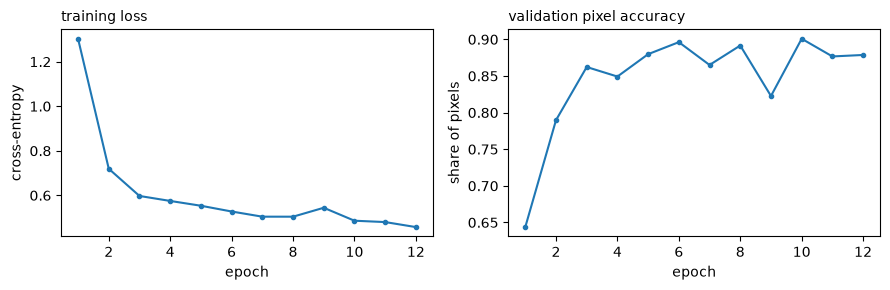

In [12]:
#@title Training loss and validation accuracy
fig, (a, b) = plt.subplots(1, 2, figsize=(9, 3))
history["train loss"].plot(ax=a, marker="."), a.set_ylabel("cross-entropy"), a.set_title("training loss", loc="left", fontsize=10)
history["val accuracy"].plot(ax=b, marker="."), b.set_ylabel("share of pixels"), b.set_title("validation pixel accuracy", loc="left", fontsize=10)
fig.tight_layout();

### 3.6 A held-out cell

The whole 1,056 x 1,056 window of one validation cell: Sentinel-2 true colour, WorldCover 2021 and the prediction.

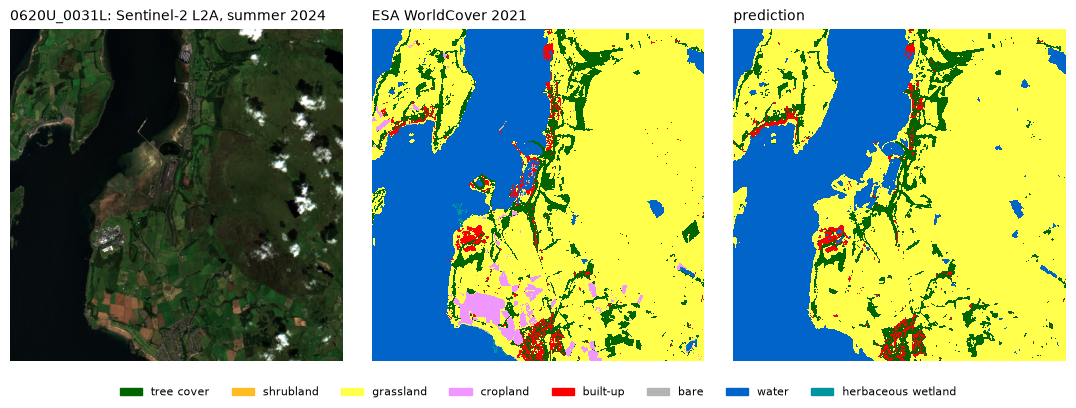

In [13]:
from matplotlib.colors import ListedColormap

COLOURS = ["#006400", "#ffbb22", "#ffff4c", "#f096ff", "#fa0000", "#b4b4b4", "#f0f0f0", "#0064c8", "#0096a0",
           "#00cf75", "#fae6a0"]                                          # ESA WorldCover legend
row = val_table.iloc[0]
x = (rumi.read_many([row.location_s2], [row.header_s2]).astype(np.float32) - OFFSET) / SCALE
label = LOOKUP[rumi.read_many([row.location_wc], [row.header_wc])[0, 0]]
with torch.no_grad(), torch.autocast(**amp):
    pred = model.eval()(torch.from_numpy(x).to(device)).argmax(1)[0].cpu().numpy()
fig, axes = plt.subplots(1, 3, figsize=(11, 3.9))
axes[0].imshow(np.clip(x[0, [2, 1, 0]].transpose(1, 2, 0) * 3.5, 0, 1))
for ax, classes in zip(axes[1:], (np.ma.masked_equal(label, 255), pred)):           # blank: no label
    ax.imshow(classes, cmap=ListedColormap(COLOURS), vmin=-0.5, vmax=len(COLOURS) - 0.5, interpolation="nearest")
for ax, title in zip(axes, ("Sentinel-2 L2A, summer 2024", "ESA WorldCover 2021", "prediction")):
    ax.set_title(f"{row.cell[7:]}: {title}" if title.startswith("Sentinel") else title, loc="left", fontsize=10), ax.axis("off")
present = sorted(set(np.unique(label)) - {255})
fig.legend([plt.Rectangle((0, 0), 1, 1, color=COLOURS[k]) for k in present], [list(CLASSES.values())[k] for k in present],
           loc="lower center", ncol=len(present), fontsize=8, frameon=False)
fig.tight_layout(rect=(0, 0.07, 1, 1));

### 3.7 Training from a published TACO dataset

A TACO dataset opens from its URL: `taco.open_dataset` reads the catalogue, and the file locations it returns are
GDAL paths over HTTP, so the same `Crops` Dataset reads batches straight from source.coop. Here: Sentinel-2 L2A
from `major-tom/release-test` (built with `majortom.build` and released with `majortom.release`).

In [14]:
url = "https://data.source.coop/major-tom/release-test/sentinel-2-l2a/"
query = 'SELECT "majortom:code" AS cell, "10m.rumi::location" AS location, "10m.rumi::header" AS header FROM dataset'
remote = taco.open_dataset(url).sql(query).to_pandas()
start = time.perf_counter()
x = rumi.read_many(list(remote.location), list(remote.header))            # every sample's 10 m file, over HTTP
print(len(remote), "samples from", url, "->", x.shape, x.dtype, f"in {time.perf_counter() - start:.1f} s")

6 samples from https://data.source.coop/major-tom/release-test/sentinel-2-l2a/ -> (6, 4, 1056, 1056) uint16 in 1.0 s


## 4. Next

- More cells: `build.cells_in` takes a box or a polygon; `workers` in `build.download` builds samples in parallel.
- Other inputs and labels: any product of `majortom.build` (current list:
  [ARCHIVES.md section 2](https://github.com/ESA-PhiLab/Major-TOM/blob/refactor/v1/docs/ARCHIVES.md)), e.g. Sentinel-1 RTC as a second input.
- Publish the TACO datasets (then train from their URL as in section 3.7): [00-Major-TOM](https://github.com/ESA-PhiLab/Major-TOM/blob/refactor/v1/00-Major-TOM.ipynb), sections 5 and 6.
- The CNG 2026 workshop compares reading GeoTIFF and rumi per epoch: [workshop notebook](https://github.com/ESA-PhiLab/Major-TOM/blob/refactor/v1/docs/workshop/workshop.ipynb), section 10.